# Deteksi Transaksi Fraud Kartu Kredit Menggunakan Metode Klasifikasi

**Notebook:** Business Understanding, Data Gathering, EDA, Data Cleaning, Preprocessing, Seleksi Fitur, Modeling, Evaluasi, dan Konklusi
**Mata kuliah:** Data Science (IF-A) | **Dosen pengampu:** Dhimas Arief Dharmawan

| No | Nama | NIM |
|----|------|-----|
| 1 | Farabian Nabil Alauzi | 123240058 |
| 2 | Waladi Lintang Novianto | 123240065 |
| 3 | Raflin Madani | 123240078 |
| 4 | Raihan Buono Putra | 123240090 |

Program Studi Informatika, Fakultas Teknik Industri, Universitas Pembangunan Nasional "Veteran" Yogyakarta, 2026

---

**Daftar isi**
1. Business Understanding
2. Data Gathering
3. Exploratory Data Analysis (EDA)
4. Data Cleaning
5. Preprocessing
6. Seleksi Fitur
7. Modeling
8. Evaluasi
9. Konklusi

Notebook ini memuat seluruh alur klasifikasi deteksi fraud, mulai dari pemahaman bisnis hingga evaluasi model. Pastikan file `creditcard_1000.csv` berada pada folder yang sama dengan notebook sebelum menjalankan seluruh sel secara berurutan.

**Cara membaca kode.** Langkah utama ditulis berurutan seperti modul. Baca CSV langsung, pisahkan fitur dan target, split, scaling, fit, predict, dan evaluasi. Bagian validasi silang dan seleksi fitur merupakan tambahan untuk mendukung keputusan. Penjelasan hasil ditulis sebagai sel Markdown biasa berdasarkan eksekusi yang tersimpan.

# 1. Business Understanding

## 1.1 Latar Belakang dan Permasalahan Bisnis

Penipuan transaksi kartu kredit (*credit card fraud*) menimbulkan kerugian finansial langsung bagi bank penerbit dan memicu penurunan kepercayaan nasabah. Volume transaksi harian yang masif membuat proses verifikasi manual mustahil memeriksa seluruh transaksi satu per satu. Oleh karena itu, sistem klasifikasi otomatis dibutuhkan untuk menyaring transaksi mencurigakan secara terukur agar analis fraud dapat memprioritaskan investigasi pada transaksi berisiko tertinggi.

Proyek ini membangun dan membandingkan model klasifikasi menggunakan algoritma **Support Vector Machine (SVM)** dan **Random Forest**. Fokus pemodelan adalah menemukan sebanyak mungkin transaksi penipuan (recall tinggi) sekaligus menekan alarm keliru pada transaksi normal (precision tinggi).

## 1.2 Pemangku Kepentingan (Stakeholders)

| No | Pemangku Kepentingan | Peran | Kepentingan terhadap Proyek |
|----|----------------------|-------|-----------------------------|
| 1 | Penerbit kartu (bank/lembaga keuangan) | Pengguna utama hasil analisis | Menekan kerugian akibat transaksi fraud, menjaga reputasi, dan memenuhi kewajiban pengelolaan risiko |
| 2 | Tim analis fraud / manajemen risiko | Pengguna operasional | Mendapatkan prioritas transaksi berisiko tinggi agar peninjauan manual lebih efisien dan terarah |
| 3 | Pemegang kartu (nasabah) | Pihak yang terdampak langsung | Terlindungi dari penyalahgunaan kartu, sekaligus tidak mengalami penolakan transaksi sah yang tidak perlu |
| 4 | Merchant | Pihak yang terdampak | Mengurangi kerugian akibat *chargeback* dan menjaga kelancaran transaksi pelanggan |
| 5 | Tim data science (penulis) | Pelaksana proyek | Memahami masalah dan data, serta menyiapkan dasar yang tepat untuk preprocessing dan pemodelan |
| 6 | Dosen pengampu dan Program Studi Informatika | Pemberi tugas dan penilai | Menilai pemahaman penerapan alur CRISP-DM pada kasus nyata |
| 7 | Penyedia dataset (ULB Machine Learning Group) | Pemilik data | Data digunakan sesuai informasi lisensi dan untuk tujuan akademik |

Karena proyek berskala akademik, pemangku kepentingan nomor 1-4 adalah pihak yang dibayangkan (*hypothetical*) dalam skenario bisnis, sedangkan nomor 5-7 terlibat langsung dalam pelaksanaan proyek.

### Pemetaan stakeholder dan data

| Stakeholder | Kebutuhan | Kolom pendukung analisis | Kegunaan hasil |
|---|---|---|---|
| Bank / penerbit kartu | Mengenali transaksi berisiko fraud | Time, Amount, V1-V28; Class sebagai label historis | Mendukung pengelolaan risiko dan peninjauan |
| Tim fraud / risk analyst | Menentukan prioritas pemeriksaan | Seluruh fitur prediktor serta label Class saat pelatihan/evaluasi | Mengurutkan transaksi yang memerlukan pemeriksaan |
| Pemegang kartu | Mengurangi penyalahgunaan dan gangguan transaksi sah | Amount, Time, Class dalam analisis historis | Mendapat manfaat dari deteksi yang lebih tepat |
| Merchant | Mengurangi potensi kerugian dan gangguan transaksi | Amount, Time, Class dalam analisis historis | Mendapat manfaat dari berkurangnya transaksi fraud |
| Tim data science | Memeriksa kualitas data dan membangun model | Seluruh 31 kolom pada analisis historis | Melakukan EDA, preprocessing, pelatihan, dan evaluasi |

Class digunakan sebagai jawaban historis untuk belajar dan mengevaluasi. Saat transaksi baru diprediksi, input model terdiri dari 30 fitur. Stakeholder operasional memakai hasil penilaian risiko model untuk membantu peninjauan.

## 1.3 Tujuan SMART

**Tujuan 1 - Pemahaman bisnis dan data (Progress 1)**

| Aspek | Uraian |
|-------|--------|
| Specific | Menyusun Business Understanding dan Data Understanding untuk dataset Credit Card Fraud Detection: pemangku kepentingan, tujuan, asumsi, risiko, struktur data, kualitas data, dan EDA |
| Measurable | Kualitas data terdokumentasi (missing value, duplikat, kandidat outlier) dan rasio kelas teridentifikasi (492 fraud dari 284.807 transaksi pada dataset lengkap) |
| Achievable | Dataset tersedia terbuka di Kaggle, berstruktur tabular, dan tidak memiliki missing value sehingga dapat dianalisis dengan pandas, numpy, matplotlib, dan seaborn |
| Relevant | Menjadi dasar keputusan preprocessing, pemilihan model, dan metrik evaluasi |
| Time-bound | Diselesaikan pada laporan Progress 1 sesuai jadwal progress report |

**Tujuan 2 - Persiapan data (notebook ini)**

| Aspek | Uraian |
|-------|--------|
| Specific | Melakukan Data Gathering, EDA, Cleaning, dan Preprocessing pada `creditcard_1000.csv` (subset 1.000 transaksi) |
| Measurable | Missing value, duplikat, dan kandidat outlier terdokumentasi dan ditangani dengan alasan yang jelas; data dibagi secara stratified menjadi bagian latih dan uji untuk pemodelan |
| Achievable | Menggunakan pandas, scikit-learn, matplotlib, dan seaborn pada data tabular berukuran kecil |
| Relevant | Data yang bersih dan bebas kebocoran (*leakage*) merupakan prasyarat pemodelan yang valid |
| Time-bound | Diselesaikan dan dikumpulkan sebagai repository GitHub sebelum tenggat pengumpulan tugas di Spada |

**Tujuan 3 - Pemodelan dan evaluasi (proyek akhir)**

| Aspek | Uraian |
|-------|--------|
| Specific | Membangun model klasifikasi biner untuk membedakan transaksi fraud (`Class = 1`) dan normal (`Class = 0`) |
| Measurable | Dievaluasi dengan precision, recall, F1-score, dan AUPRC pada data uji, serta dibandingkan dengan model baseline |
| Achievable | Subset kerja hampir seimbang; gunakan stratified split dan validasi silang tanpa resampling tambahan |
| Relevant | Mendukung kebutuhan bisnis mendeteksi fraud secara dini dengan tetap meminimalkan penolakan transaksi sah |
| Time-bound | Diselesaikan sebelum tenggat proyek akhir pada 22 November 2026 |

## 1.4 Kriteria Keberhasilan

**a. Keberhasilan bisnis**
1. Permasalahan bisnis terumuskan dengan jelas sebagai klasifikasi biner untuk mengidentifikasi transaksi fraud.
2. Pemangku kepentingan, manfaat, risiko, serta batasan proyek terdokumentasi secara eksplisit.
3. Hasil analisis dapat dijadikan dasar untuk memprioritaskan transaksi berisiko tinggi agar peninjauan lebih efisien.

**b. Keberhasilan pemahaman dan persiapan data**
1. Struktur dataset (jumlah baris, kolom, dan tipe data) terdokumentasi lengkap dalam data dictionary.
2. Pemeriksaan kualitas data selesai: missing value, duplikat, dan kandidat outlier.
3. Proporsi kelas teridentifikasi dan dijadikan pertimbangan dalam pemilihan metrik.
4. Keputusan cleaning dan preprocessing diambil berdasarkan temuan EDA, tanpa menghapus duplikat atau outlier secara sembarangan.

**c. Keberhasilan model**
1. Evaluasi tidak bertumpu pada akurasi, melainkan pada precision, recall, F1-score, dan AUPRC.
2. Model harus lebih baik daripada baseline sederhana (misalnya memprediksi seluruh transaksi sebagai normal) pada AUPRC dan recall kelas fraud.
3. Laporkan false negative dan false positive pada ambang bawaan model. Penentuan biaya kerugian dan threshold operasional memerlukan informasi bisnis tambahan.
4. Hasil dapat direproduksi mengikuti notebook ini.

## 1.5 Asumsi dan Batasan Proyek

**Asumsi**
1. Label pada kolom `Class` dianggap akurat (1 = fraud, 0 = normal). Proses pelabelan oleh penyedia dataset tidak diverifikasi ulang.
2. Setiap baris mewakili satu transaksi kartu kredit yang berdiri sendiri.
3. Subset digunakan untuk mempelajari alur klasifikasi pada dataset ini; keterwakilannya dibahas melalui bias proporsi kelas, waktu, dan wilayah.
4. Fitur `V1`-`V28` dianggap telah melalui transformasi PCA sesuai dokumentasi dataset, sedangkan `Time` dan `Amount` masih berada pada skala aslinya sehingga memerlukan penyesuaian skala.
5. Data duplikat dan kandidat outlier belum tentu merupakan kesalahan data, sehingga penanganannya diputuskan berdasarkan pertimbangan analisis.

**Batasan**
1. **Cakupan tahapan:** notebook ini mencakup Business Understanding sampai Konklusi, termasuk seleksi fitur serta perbandingan SVM dan Random Forest.
2. **Cakupan waktu dan wilayah:** transaksi pemegang kartu di Eropa selama dua hari pada September 2013, sehingga belum tentu menggambarkan pola fraud pada kondisi lain.
3. **Anonimisasi fitur:** `V1`-`V28` hasil PCA sehingga makna bisnisnya tidak dapat diinterpretasikan langsung.
4. **Keterbatasan atribut:** tidak ada informasi jenis merchant, lokasi, perangkat, maupun riwayat pemegang kartu.
5. **Subset data:** dataset lengkap berisi 284.807 transaksi dengan hanya 492 fraud (sekitar 0,17%). Notebook ini memakai subset 1.000 baris (semua fraud ditambah transaksi normal yang dipilih acak), sehingga proporsi kelas **tidak lagi mencerminkan kondisi nyata**. Metrik yang diperoleh dari subset ini cenderung terlalu optimistis dibanding kondisi produksi.
6. **Sifat analisis:** analisis *offline* pada data historis, tanpa implementasi sistem deteksi *real-time*.
7. **Lisensi data:** mengikuti informasi lisensi pada Kaggle dan terbatas untuk kepentingan akademik.

## 1.6 Risiko dan Mitigasi

| No | Risiko | Dampak | Mitigasi |
|----|--------|--------|----------|
| 1 | Ketidakseimbangan kelas ekstrem (pada dataset lengkap) | Model memprediksi semua transaksi sebagai normal dan tetap tampak akurat | Gunakan precision, recall, F1-score, AUPRC; pertimbangkan class weight/resampling dan *stratified split* |
| 2 | Data duplikat | Bias dan kebocoran data bila baris yang sama muncul pada data latih dan uji | Evaluasi duplikat sebelum dihapus; pastikan data latih dan uji tidak tumpang tindih |
| 3 | Kandidat outlier yang banyak (mis. `Amount`) | Penghapusan sembarangan dapat membuang transaksi fraud bernilai ekstrem | Jangan hapus otomatis; telaah dulu dan gunakan penskalaan yang *robust* |
| 4 | Fitur teranonimkan (PCA) | Hasil model sulit dijelaskan secara bisnis | Fokus pada performa dan pola umum; catat keterbatasan interpretabilitas |
| 5 | Data tidak representatif (dua hari, Eropa, 2013, dan subset 1.000 baris) | Hasil berpotensi tidak berlaku pada data lain | Nyatakan batas generalisasi; uji ulang dengan data yang lebih baru/realistis |
| 6 | Kesalahan klasifikasi (FN dan FP) | FN membuat fraud lolos; FP menambah alarm keliru dan beban peninjauan transaksi sah | Laporkan precision, recall, FN, dan FP; pengaturan threshold berbasis biaya menjadi pekerjaan lanjutan |
| 7 | *Overfitting* pada kelas minoritas | Model baik pada data latih, buruk pada data baru | Pisahkan data latih/uji dengan tepat, gunakan validasi silang |
| 8 | Perubahan pola fraud (*concept drift*) | Performa menurun pada kondisi nyata | Rekomendasikan pemantauan dan pelatihan ulang berkala |

**Etika dan penggunaan data.** Gunakan dataset sesuai ketentuan sumber, cantumkan atribusi, dan jaga kerahasiaan data jika kelak memakai data operasional. Fitur anonim tetap memiliki batas interpretasi. Penerapan model mendukung pemeriksaan analis. Kebocoran informasi data uji dalam pelatihan dan pengungkapan data pribadi memiliki dampak serta mitigasi yang berbeda.

## 1.7 Manfaat dan Nilai Bisnis

1. **Mengurangi kerugian finansial:** identifikasi transaksi mencurigakan lebih dini membantu menekan kerugian penerbit kartu, merchant, dan pemegang kartu.
2. **Meningkatkan efisiensi pemeriksaan:** model membantu memprioritaskan transaksi berisiko tinggi untuk ditinjau analis fraud, karena pemeriksaan manual atas semua transaksi tidak praktis.
3. **Menjaga kepercayaan pelanggan:** deteksi yang akurat melindungi pemegang kartu sekaligus meminimalkan penolakan transaksi sah.
4. **Mendukung keputusan berbasis data:** pemahaman karakteristik dan kualitas data menjadi dasar objektif untuk preprocessing, pemilihan model, dan metrik.
5. **Nilai pembelajaran akademik:** contoh penerapan alur CRISP-DM pada kasus nyata yang *imbalanced*.

> Manfaat di atas bersifat potensial, bukan hasil terukur. Nilai finansial sesungguhnya baru dapat dihitung setelah model dibangun dan dievaluasi.

**Use case utama.** Menandai transaksi yang berisiko agar tim fraud dapat menentukan prioritas pemeriksaan lebih lanjut, sesuai Progress 1.

# 2. Data Gathering

## 2.1 Sumber Data dan Lisensi

Dataset yang digunakan adalah **Credit Card Fraud Detection** dari Kaggle, dipublikasikan oleh Machine Learning Group, Universite Libre de Bruxelles (ULB). Isinya transaksi kartu kredit pemegang kartu di Eropa selama dua hari pada September 2013. Informasi lisensi pada Kaggle: *Database: Open Database, Contents: Database Contents*.

- Tautan: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Dataset lengkap: 284.807 transaksi (492 fraud, 284.315 normal), 31 kolom.

## 2.2 Dataset Kerja (`creditcard_1000.csv`)

Untuk tugas ini digunakan subset **1.000 transaksi**: seluruh 492 transaksi fraud dari dataset lengkap ditambah 508 transaksi normal yang dipilih acak (`random_state=42`). Baris duplikat bawaan dataset asli **tidak dihapus** agar dapat dinilai pada tahap cleaning. Subset dibuat dengan kode berikut (tidak dijalankan di notebook ini karena memerlukan `creditcard.csv` lengkap):

```python
df_full = pd.read_csv("creditcard.csv")
fraud = df_full[df_full["Class"] == 1]
normal = df_full[df_full["Class"] == 0].sample(n=1000 - len(fraud), random_state=42)
pd.concat([fraud, normal]).sort_index().to_csv("creditcard_1000.csv", index=False)
```

## 2.3 Data Dictionary

| No | Kolom | Tipe | Deskripsi |
|----|-------|------|-----------|
| 1 | `Time` | Numerik | Waktu transaksi dalam detik sejak transaksi pertama dalam dataset |
| 2-29 | `V1` - `V28` | Numerik | Fitur hasil transformasi PCA (dianonimkan untuk menjaga kerahasiaan) |
| 30 | `Amount` | Numerik | Nominal transaksi (satuan mata uang tidak dinyatakan pada file) |
| 31 | `Class` | Numerik (biner) | Variabel target: 0 = transaksi normal, 1 = fraud |

**Pembedaan desain sampel.** Subset 1.000 baris diperkaya kelas fraud. Analisis sampel acak 100.000 baris pada notebook UTS merupakan analisis terpisah. Notebook terpadu ini memakai subset 1.000 baris secara konsisten.

**Penggunaan kamus data.** Time diukur dalam detik sejak transaksi pertama. Amount adalah nominal transaksi; berkas CSV dan kamus data proyek tidak menetapkan USD sebagai unitnya. Seluruh prediktor numerik, dan Class adalah label biner.

## Impor Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Memuat Data

In [2]:
df = pd.read_csv("creditcard_1000.csv")
display(df.head())
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1
1,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.661696,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1
2,607.0,1.038261,-0.301415,0.910167,0.863872,-0.741702,0.090125,-0.409753,0.076723,0.684990,...,0.134996,0.554309,-0.138944,0.168500,0.423859,0.530611,0.014980,0.028041,69.99,0
3,861.0,-0.945987,1.232753,0.820313,0.311064,0.981736,0.935188,0.566926,-0.008604,-0.621912,...,0.124922,0.284644,-0.197951,-1.326061,-0.161715,-0.382919,-0.488500,0.144470,10.00,0
4,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,...,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     1000 non-null   float64
 22  V22     1000

# 3. Exploratory Data Analysis (EDA)

## 3.1 Gambaran Umum Dataset

In [3]:
# Cek Dataset
print(f"Ukuran Dataset: {df.shape} \n")

print(f"Tipe Data :")
df.info()

print("\nStatistik Deskriptif: ")
display(df.describe().T)

Ukuran Dataset: (1000, 31) 

Tipe Data :
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     

,count,mean,std,min,25%,50%,75%,max
Time,1000.0,88105.316000,48076.754070,406.000000,46099.750000,81348.000000,134766.750000,171917.000000
V1,1000.0,-2.269096,5.490748,-30.552380,-2.732232,-0.741705,1.134074,2.351891
V2,1000.0,1.782844,3.659953,-8.402154,-0.173693,0.903714,2.777569,22.057729
V3,1000.0,-3.479627,6.168222,-31.103685,-5.049001,-1.326710,0.242719,3.143387
V4,1000.0,2.224461,3.198678,-4.519509,-0.177790,1.275632,4.173330,12.114672
V5,1000.0,-1.521588,4.177193,-22.105532,-1.736819,-0.336980,0.493738,11.095089
V6,1000.0,-0.715315,1.718498,-6.406267,-1.572363,-0.664051,0.080004,6.474115
V7,1000.0,-2.733041,5.810310,-43.557242,-3.028330,-0.608816,0.288919,5.802537
V8,1000.0,0.284916,4.821946,-41.044261,-0.229344,0.137477,0.855025,20.007208
V9,1000.0,-1.253420,2.332128,-13.434066,-2.331368,-0.695574,0.194952,5.232322


## 3.2 Distribusi Kelas

       Jumlah  Persentase (%)
Class                        
0         508            50.8
1         492            49.2


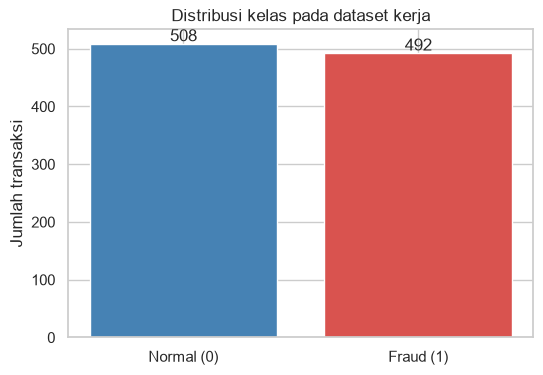

In [4]:
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"Jumlah": class_counts, "Persentase (%)": class_pct.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4682B4", "#D9534F"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 5, int(b.get_height()), ha="center")
ax.set_ylabel("Jumlah transaksi")
ax.set_title("Distribusi kelas pada dataset kerja")
plt.show()

Dataset kerja hampir seimbang karena merupakan hasil pengambilan **seluruh fraud** dan **sebagian transaksi normal**. Pada dataset lengkap proporsi fraud hanya sekitar 0,17%, jadi hasil EDA dan model dari subset ini tidak boleh langsung dianggap mewakili kondisi nyata.

### Representativitas dan Bias Sampel

Subset 1.000 transaksi memuat seluruh 492 transaksi fraud dan 508 transaksi normal yang dipilih secara acak. Komposisi fraud sebesar 49,2% pada subset ini berbeda signifikan dari proporsi populasi aslinya (~0,173%). Desain pengayaan kelas ini bertujuan melatih model mengenali pola fraud secara efektif pada data berukuran ringkas.

Uji representativitas sampel acak terhadap data penuh menunjukkan nilai simpangan baku rata-rata terstandarisasi (Standardized Mean Difference / SMD) maksimum hanya sebesar 0,0044 (|SMD| < 0,10) dan nilai p-value uji Kolmogorov-Smirnov di atas 0,05. Hal ini membuktikan bahwa distribusi fitur transaksi normal pada sampel tetap konsisten dengan populasi data asalnya.

**Analisis Tambahan (Opsional):** Sel kode di bawah memverifikasi representativitas sampel jika dataset penuh (`creditcard.csv`) tersedia di folder `archive/`. Secara bawaan, variabel `jalankan_studi_tambahan` bernilai `False` sehingga alur eksekusi langsung berfokus pada dataset kerja `creditcard_1000.csv`.

In [5]:
jalankan_studi_tambahan = False

if jalankan_studi_tambahan:
    df_full = pd.read_csv("../archive/creditcard.csv")
    sampel_acak = df_full.sample(n=100000, random_state=42)

    print("Transaksi pada data penuh:", len(df_full))
    print("Transaksi pada sampel acak:", len(sampel_acak))
    print("Persentase fraud data penuh:", df_full["Class"].mean() * 100)
    print("Persentase fraud sampel acak:", sampel_acak["Class"].mean() * 100)

    hasil_smd = []
    for kolom in df_full.columns:
        rata_populasi = df_full[kolom].mean()
        rata_sampel = sampel_acak[kolom].mean()
        varians_populasi = df_full[kolom].var()
        varians_sampel = sampel_acak[kolom].var()
        simpangan_gabungan = np.sqrt((varians_populasi + varians_sampel) / 2)
        smd = (rata_sampel - rata_populasi) / simpangan_gabungan
        hasil_smd.append([kolom, smd])

    tabel_smd = pd.DataFrame(hasil_smd, columns=["Fitur", "SMD"])
    print("SMD absolut maksimum:", tabel_smd["SMD"].abs().max())
    display(tabel_smd.round(4))
else:
    print("Studi tambahan dilewati. Analisis utama menggunakan creditcard_1000.csv.")

Studi tambahan dilewati. Analisis utama menggunakan creditcard_1000.csv.


## 3.3 Distribusi Nilai Transaksi (`Amount`)

       count    mean     std  min   25%    50%     75%      max
Class                                                          
0      508.0   81.44  177.45  0.0  4.14  19.98   70.16  1464.94
1      492.0  122.21  256.68  0.0  1.00   9.25  105.89  2125.87

Persentil ke-99 Amount: 1219.12


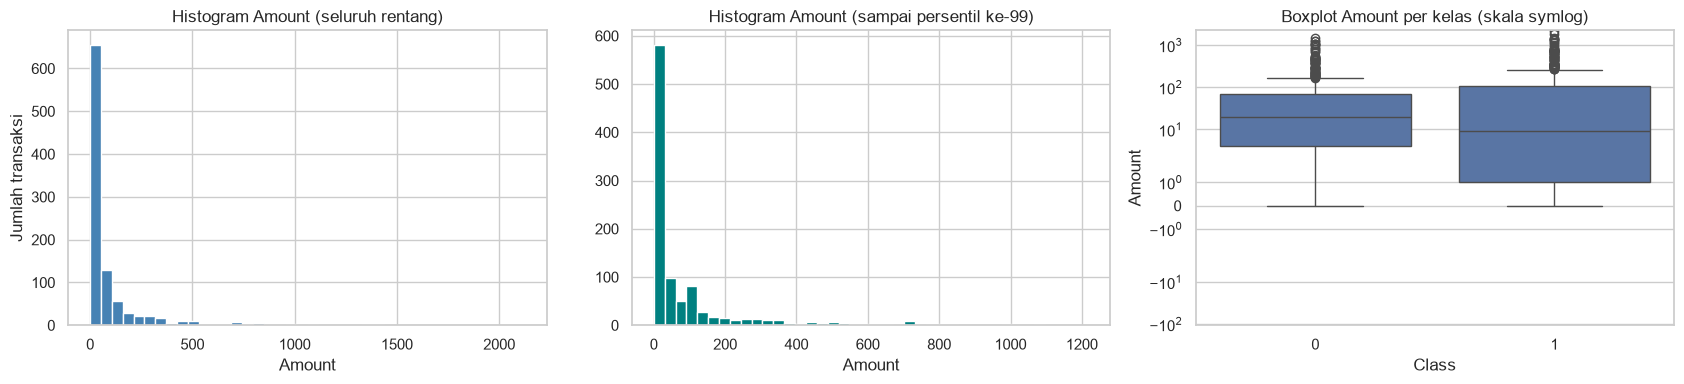

In [6]:
print(df.groupby("Class")["Amount"].describe().round(2))

p99 = df["Amount"].quantile(0.99)
print(f"\nPersentil ke-99 Amount: {p99:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(df["Amount"], bins=40, color="#4682B4")
axes[0].set_title("Histogram Amount (seluruh rentang)")
axes[0].set_xlabel("Amount"); axes[0].set_ylabel("Jumlah transaksi")

axes[1].hist(df.loc[df["Amount"] <= p99, "Amount"], bins=40, color="teal")
axes[1].set_title("Histogram Amount (sampai persentil ke-99)")
axes[1].set_xlabel("Amount")

sns.boxplot(data=df, x="Class", y="Amount", ax=axes[2])
axes[2].set_yscale("symlog")
axes[2].set_title("Boxplot Amount per kelas (skala symlog)")
plt.tight_layout()
plt.show()

Distribusi `Amount` memiliki kemiringan positif yang tajam (*right-skewed*) dengan nilai rata-rata yang jauh melampaui median. Karakteristik ini membuat fitur `Amount` sensitif terhadap nilai ekstrem, sehingga memerlukan penskalaan berbasis median dan rentang interkuartil (`RobustScaler`) pada tahap prapemrosesan.

## 3.4 Distribusi Waktu (`Time`)

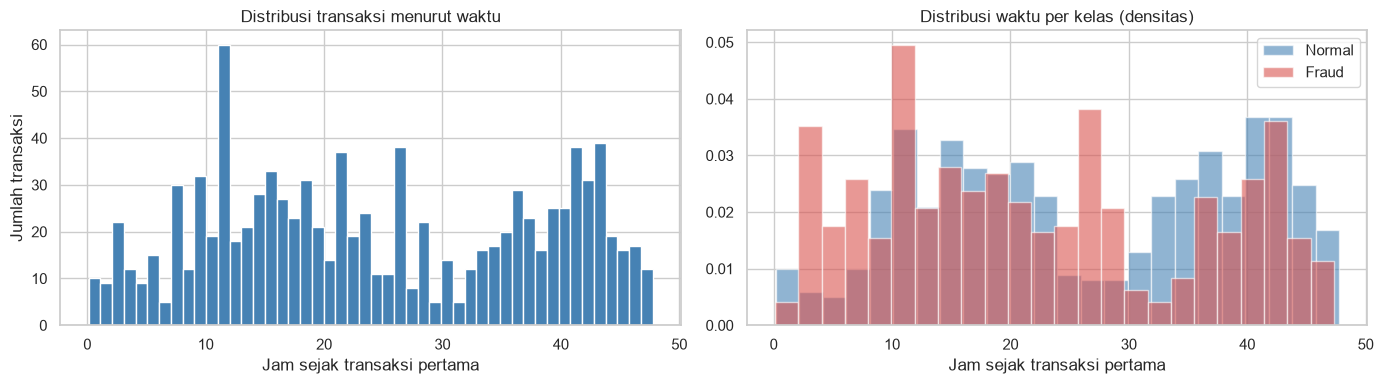

In [7]:
df_time = df.assign(Jam=df["Time"] / 3600)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_time["Jam"], bins=48, color="#4682B4")
axes[0].set_title("Distribusi transaksi menurut waktu")
axes[0].set_xlabel("Jam sejak transaksi pertama"); axes[0].set_ylabel("Jumlah transaksi")

for kelas, warna, label in [(0, "#4682B4", "Normal"), (1, "#D9534F", "Fraud")]:
    axes[1].hist(df_time.loc[df_time["Class"] == kelas, "Jam"], bins=24, alpha=0.6,
                 color=warna, label=label, density=True)
axes[1].set_title("Distribusi waktu per kelas (densitas)")
axes[1].set_xlabel("Jam sejak transaksi pertama"); axes[1].legend()
plt.tight_layout()
plt.show()

Distribusi Time kedua kelas tumpang tindih. Time tetap diuji pada set lengkap untuk melihat kontribusinya bersama fitur lain.

## 3.5 Korelasi Fitur dengan Target

V14   -0.751
V4     0.713
V11    0.687
V12   -0.685
V10   -0.632
V16   -0.600
V3    -0.567
V17   -0.562
V9    -0.561
V2     0.495
Name: Class, dtype: float64

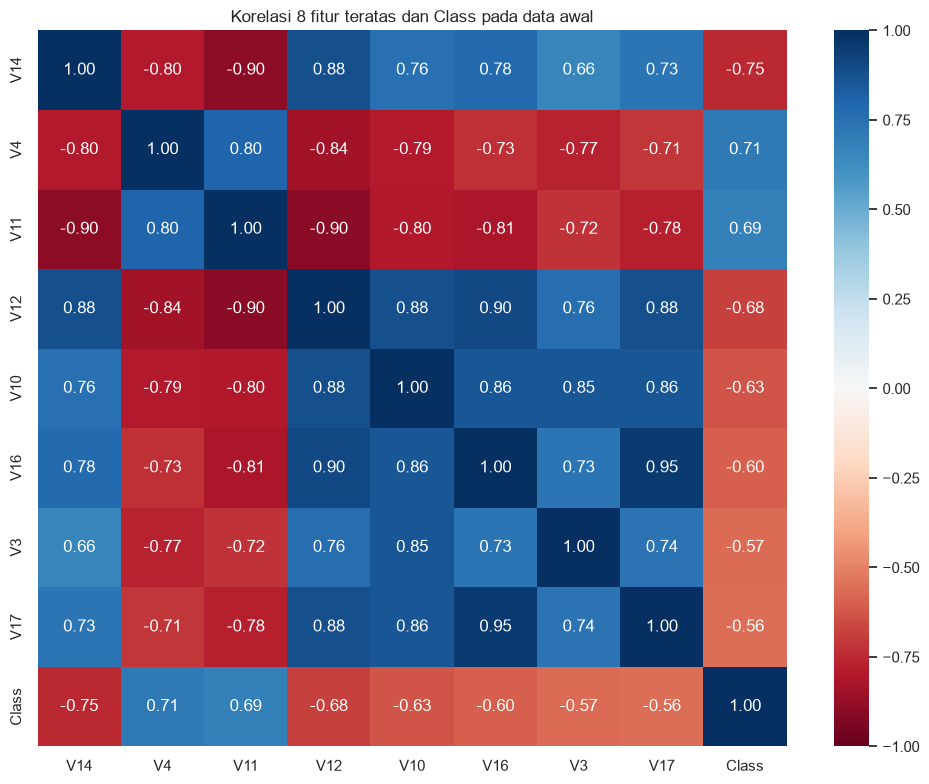

In [8]:
korelasi_target = df.corr()["Class"].drop("Class")
urutan = korelasi_target.abs().sort_values(ascending=False)
korelasi_target = korelasi_target.loc[urutan.index]
display(korelasi_target.head(10).round(3))

top_feats = korelasi_target.head(8).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_feats + ["Class"]].corr(), annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1)
plt.title("Korelasi 8 fitur teratas dan Class pada data awal")
plt.tight_layout()
plt.show()

Korelasi Pearson mengukur hubungan linear. Komposisi kelas dapat memengaruhi nilainya, sehingga korelasi pada subset ini perlu dibaca sesuai desain sampling. Pemilihan fitur pada bab 6 dihitung ulang dari data latih di dalam setiap fold validasi.

## 3.6 Perbandingan Distribusi Fitur Teratas per Kelas

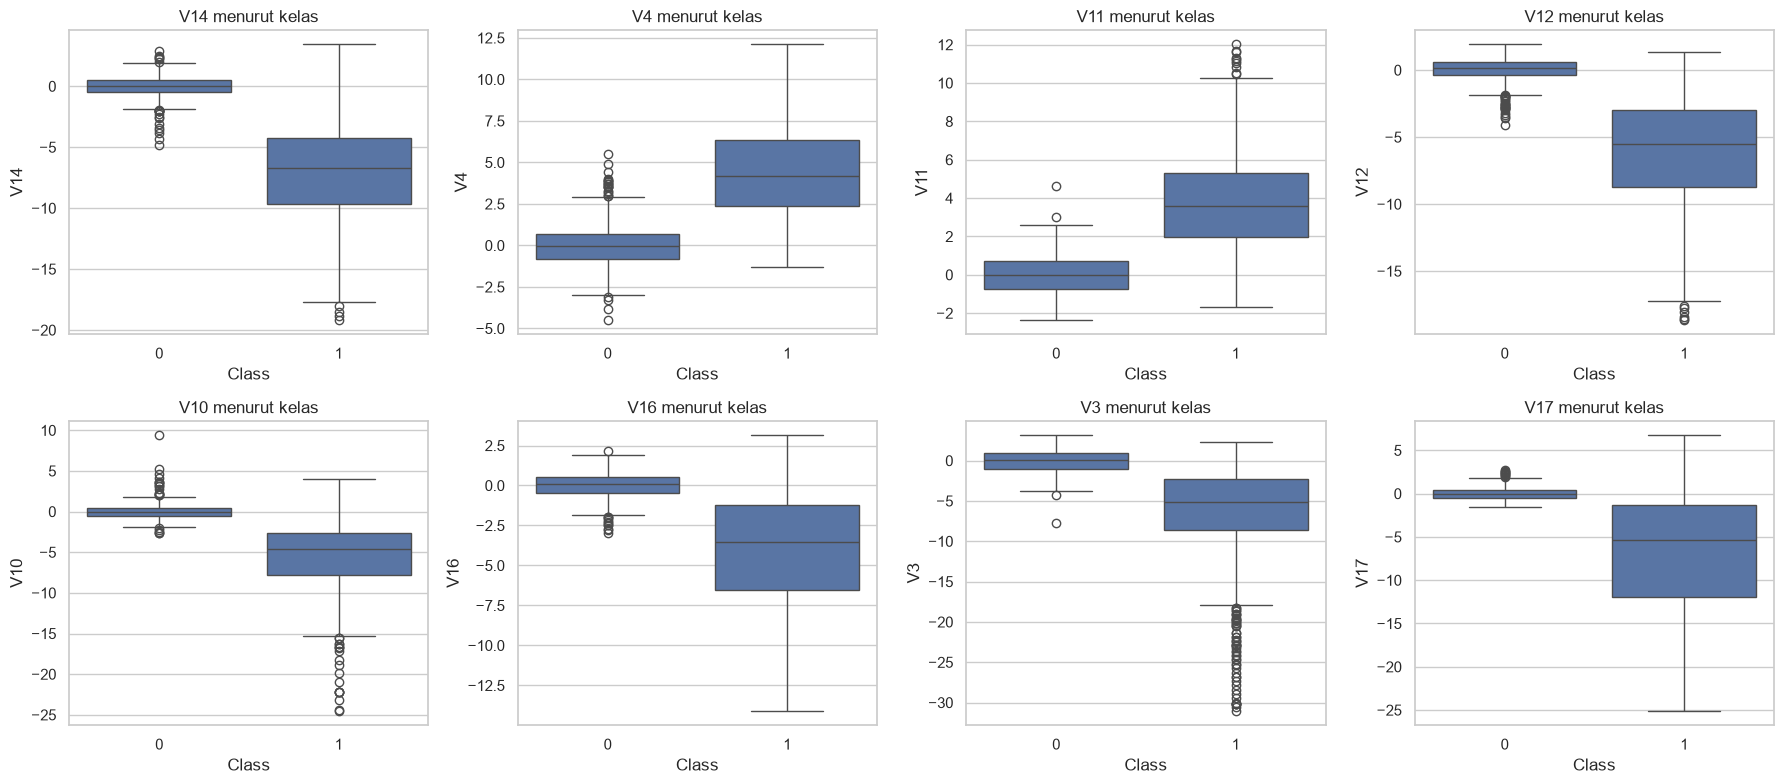

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feat in zip(axes.ravel(), top_feats):
    sns.boxplot(data=df, x="Class", y=feat, ax=ax)
    ax.set_title(f"{feat} menurut kelas")
plt.tight_layout()
plt.show()

Pada subset ini, median V14, V12, dan V10 untuk fraud lebih rendah, sedangkan V4 dan V11 lebih tinggi. Pola tersebut menjadi kandidat untuk diuji pada data latih. Makna bisnis asli komponen PCA tetap tidak tersedia.

## 3.7 Pemeriksaan Kualitas Data (Missing Value dan Duplikat)

### Batas pembacaan angka sebelum dan sesudah cleaning

Seluruh tabel statistik per kelas dan korelasi Pearson pada bab 3 memakai subset awal 1.000 transaksi, sama dengan grafik EDA Progress 2. Jumlah outlier berubah ketika 19 duplikat dihapus pada bab 4. Kandidat outlier Amount adalah 116 pada data awal dan 113 pada data bersih. Jumlah Amount = 0 adalah 33 sebelum cleaning dan 31 sesudahnya. Dua hitungan ini memiliki penyebut dan tahap pemrosesan masing-masing.

In [10]:
# Tangani Data Kotor
print("\nMissing Values: ")
print(df.isnull().sum())

print(f"\nData Duplikat: {df.duplicated().sum()}")


Missing Values: 
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Duplikat: 19


## 3.8 Pemeriksaan Kandidat Outlier (Metode IQR)

,Fitur,Jumlah outlier,Persentase (%),Batas bawah,Batas atas
0,V8,167,16.7,-1.856,2.482
1,V27,157,15.7,-0.837,1.226
2,V28,138,13.8,-0.456,0.608
3,V23,134,13.4,-0.886,0.840
4,V5,127,12.7,-5.083,3.840
5,V7,125,12.5,-8.004,5.265
6,V20,125,12.5,-1.163,1.437
7,Amount,116,11.6,-146.760,248.040
8,V21,110,11.0,-1.396,1.871
9,V18,102,10.2,-4.864,3.476


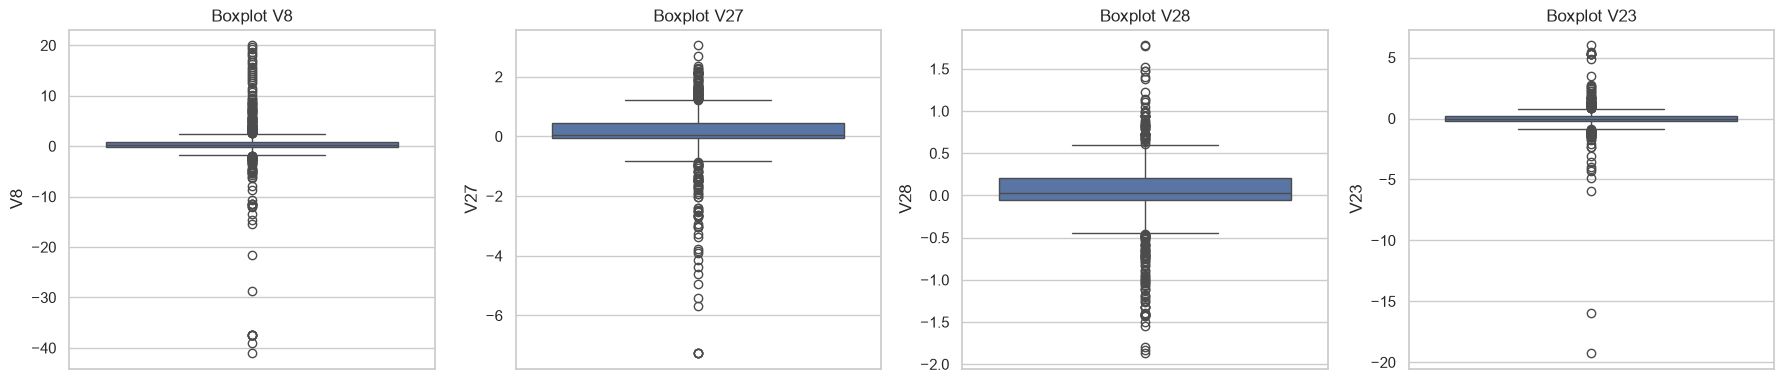

In [11]:
def hitung_outlier_iqr(data, kolom):
    q1, q3 = data[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (data[kolom] < batas_bawah) | (data[kolom] > batas_atas)
    return mask.sum(), batas_bawah, batas_atas

fitur = df.drop(columns="Class").columns
ringkas = []
for k in fitur:
    n, lo, hi = hitung_outlier_iqr(df, k)
    ringkas.append({"Fitur": k, "Jumlah outlier": n, "Persentase (%)": round(n / len(df) * 100, 2),
                    "Batas bawah": round(lo, 3), "Batas atas": round(hi, 3)})

tabel_outlier = pd.DataFrame(ringkas).sort_values("Jumlah outlier", ascending=False)
display(tabel_outlier.reset_index(drop=True))

top_out = tabel_outlier["Fitur"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, top_out):
    sns.boxplot(y=df[f], ax=ax)
    ax.set_title(f"Boxplot {f}")
plt.tight_layout()
plt.show()

# 4. Data Cleaning

Cleaning dilakukan pada salinan data (`df_clean`) agar data asli (`df`) tetap tersedia sebagai pembanding.

## 4.1 Penanganan Missing Value

In [12]:
df_clean = df.copy()
print("Jumlah missing value:", df_clean.isnull().sum().sum())
print("Dataset ini tidak memiliki missing value sehingga tidak memerlukan imputasi.")

Jumlah missing value: 0
Dataset ini tidak memiliki missing value sehingga tidak memerlukan imputasi.


## 4.2 Penanganan Data Duplikat

Karena tidak ada ID transaksi, baris yang identik pada seluruh kolom tidak pasti merupakan kesalahan pencatatan. Namun baris identik yang tersebar di data latih dan data uji menimbulkan **kebocoran data (*data leakage*)** dan membuat performa model tampak lebih baik dari seharusnya. Karena itu duplikat diperiksa dulu, lalu dihapus (menyisakan kemunculan pertama).

In [13]:
mask_dup_semua = df_clean.duplicated(keep=False)   # semua salinan, termasuk yang pertama
mask_dup_lebih = df_clean.duplicated(keep="first") # hanya salinan kelebihan

print(f"Baris yang punya kembaran (semua salinan): {mask_dup_semua.sum()}")
print(f"Baris duplikat kelebihan yang akan dihapus: {mask_dup_lebih.sum()}")
print("\nDistribusi kelas pada baris duplikat kelebihan:")
print(df_clean.loc[mask_dup_lebih, "Class"].value_counts())

print("\nContoh baris duplikat:")
display(df_clean[mask_dup_semua].sort_values(["Time", "Amount"]).head(8))

Baris yang punya kembaran (semua salinan): 32
Baris duplikat kelebihan yang akan dihapus: 19

Distribusi kelas pada baris duplikat kelebihan:
Class
1    19
Name: count, dtype: int64

Contoh baris duplikat:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
410,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
411,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
412,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
413,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
414,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
415,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
512,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1
513,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1


In [14]:
sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Jumlah baris sebelum : {sebelum}")
print(f"Jumlah baris sesudah : {len(df_clean)}")
print(f"Duplikat tersisa     : {df_clean.duplicated().sum()}")
print("\nDistribusi kelas setelah penghapusan duplikat:")
print(df_clean["Class"].value_counts().sort_index())

Jumlah baris sebelum : 1000
Jumlah baris sesudah : 981
Duplikat tersisa     : 0

Distribusi kelas setelah penghapusan duplikat:
Class
0    508
1    473
Name: count, dtype: int64


Seluruh duplikat berada pada kelas fraud, sehingga penghapusan duplikat mengurangi jumlah sampel fraud, sedangkan jumlah transaksi normal tidak berubah.

## 4.3 Penanganan Outlier

Kandidat outlier dipertahankan karena dapat memuat informasi fraud. RobustScaler dipakai untuk Amount pada Pipeline SVM. Transformasi skala mempertahankan observasi ekstrem dan mengubah ukuran numeriknya. Random Forest menggunakan nilai numerik asli.

In [15]:
# Periksa sebaran kandidat outlier Amount menurut kelas
n_out, lo, hi = hitung_outlier_iqr(df_clean, "Amount")
mask_out_amount = (df_clean["Amount"] < lo) | (df_clean["Amount"] > hi)
print(f"Batas IQR Amount: [{lo:.2f}, {hi:.2f}]")
print(f"Kandidat outlier Amount: {n_out} ({n_out / len(df_clean) * 100:.2f}%)")
print("\nKelas pada kandidat outlier Amount:")
print(df_clean.loc[mask_out_amount, "Class"].value_counts())

# Transaksi bernilai nol
n_nol = (df_clean["Amount"] == 0).sum()
print(f"\nTransaksi dengan Amount = 0: {n_nol}")
print(df_clean.loc[df_clean["Amount"] == 0, "Class"].value_counts().rename("Jumlah per kelas"))

Batas IQR Amount: [-146.76, 248.04]
Kandidat outlier Amount: 113 (11.52%)

Kelas pada kandidat outlier Amount:
Class
1    71
0    42
Name: count, dtype: int64

Transaksi dengan Amount = 0: 31
Class
1    25
0     6
Name: Jumlah per kelas, dtype: int64


Sebanyak 31 transaksi dengan Amount = 0 dipertahankan karena data sumber tidak menyediakan bukti bahwa nilainya salah. Jenis transaksi yang menyebabkan nominal nol tidak tersedia.

## 4.4 Validasi Hasil Cleaning

In [16]:
ringkasan_cleaning = pd.DataFrame({
    "Sebelum": [
        len(df), (df["Class"] == 0).sum(), (df["Class"] == 1).sum(),
        df.isnull().sum().sum(), df.duplicated().sum(),
        hitung_outlier_iqr(df, "Amount")[0], (df["Amount"] == 0).sum(),
    ],
    "Sesudah": [
        len(df_clean), (df_clean["Class"] == 0).sum(), (df_clean["Class"] == 1).sum(),
        df_clean.isnull().sum().sum(), df_clean.duplicated().sum(),
        hitung_outlier_iqr(df_clean, "Amount")[0], (df_clean["Amount"] == 0).sum(),
    ],
}, index=["Jumlah baris", "Normal", "Fraud", "Missing value", "Duplikat", "Outlier Amount", "Amount = 0"])
display(ringkasan_cleaning)

,Sebelum,Sesudah
Jumlah baris,1000,981
Normal,508,508
Fraud,492,473
Missing value,0,0
Duplikat,19,0
Outlier Amount,116,113
Amount = 0,33,31


# 5. Preprocessing

Urutan langkah dibuat agar bebas kebocoran data: **pisahkan data latih dan uji dahulu, baru lakukan penskalaan** dengan parameter yang dipelajari hanya dari data latih.

## 5.1 Pemisahan Fitur dan Target

### Rasionalisasi Prapemrosesan Fitur

Algoritma SVM linear berbasis margin jarak sensitif terhadap variasi rentang skala nilai fitur, sehingga membutuhkan penskalaan numerik (`StandardScaler` dan `RobustScaler`). Sebaliknya, Random Forest mempartisi data secara non-parametrik menggunakan pohon keputusan sehingga dapat bekerja langsung pada skala asli fitur. Pembagian data latih dan uji menggunakan metode *stratified split* untuk menjamin proporsi kelas target tetap seimbang di kedua subset.

In [17]:
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

Bentuk X: (981, 30) | Bentuk y: (981,)


## 5.2 Pembagian Data Latih dan Uji (Stratified)

Pembagian 80:20 dengan `stratify=y` agar proporsi fraud pada data latih dan uji sama dengan data keseluruhan.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Data latih: {X_train.shape[0]} baris | Data uji: {X_test.shape[0]} baris\n")
dist = pd.DataFrame({
    "Seluruh data": y.value_counts(normalize=True).sort_index() * 100,
    "Latih": y_train.value_counts(normalize=True).sort_index() * 100,
    "Uji": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
dist.index = ["Normal (0) %", "Fraud (1) %"]
display(dist)

Data latih: 784 baris | Data uji: 197 baris



,Seluruh data,Latih,Uji
Normal (0) %,51.78,51.79,51.78
Fraud (1) %,48.22,48.21,48.22


## 5.3 Scaling untuk SVM

Ikuti pola manual Modul 6, yaitu fit_transform pada data latih dan transform pada data uji. Amount menggunakan median dan IQR melalui RobustScaler. Time dan V1-V28 menggunakan StandardScaler. Salinan data berskala dipakai SVM, sementara Random Forest memakai X_train dan X_test pada skala asal.

Pada validasi silang, scaler akan dibuat ulang dan dipelajari hanya dari bagian latih masing-masing fold.

In [19]:
# Salinan data untuk SVM, agar data asli tetap tersedia untuk Random Forest.
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler_amount = RobustScaler()
X_train_scaled[["Amount"]] = scaler_amount.fit_transform(X_train[["Amount"]])
X_test_scaled[["Amount"]] = scaler_amount.transform(X_test[["Amount"]])

kolom_standard = X_train.drop(columns="Amount").columns
scaler_standard = StandardScaler()
X_train_scaled[kolom_standard] = scaler_standard.fit_transform(X_train[kolom_standard])
X_test_scaled[kolom_standard] = scaler_standard.transform(X_test[kolom_standard])

display(X_train_scaled.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
4,-1.772909,0.159930,-0.335785,0.985761,-0.245943,0.389708,1.023868,0.623849,-0.271077,1.277188,...,0.253773,-0.421243,-0.365425,0.059470,0.255664,-0.048373,-1.118201,-0.583420,-0.906691,0.278898
374,-0.495210,0.272988,-0.379039,0.858247,-1.155550,0.418410,1.058214,0.437800,0.012218,0.745921,...,-0.147930,-0.150175,-0.095191,-0.226034,-1.950207,-0.119190,1.964607,0.211012,0.251085,-0.154224
895,1.407064,0.217113,0.991669,-0.830971,1.578867,0.361532,-0.840086,-0.128706,0.324480,-1.399903,...,0.593013,0.162032,-0.513679,0.088192,-1.833904,0.035995,1.094769,0.509248,0.250180,-0.156551
438,-0.284596,-0.113030,-0.111355,0.386424,-0.157681,0.182802,-0.044092,-0.006528,0.133105,0.050496,...,-0.177128,0.152732,0.205670,-0.596521,-0.015397,0.250856,-1.012194,0.296772,0.433436,0.002429
167,-1.015996,0.037985,-0.656061,0.488597,-1.693309,0.559939,2.749847,0.593087,0.161058,0.968864,...,-0.307050,-0.030268,0.221370,-0.263494,1.873402,1.563208,-1.643330,-0.099967,-0.480343,3.377539


## 5.4 Periksa pembagian data

Tampilkan jumlah fitur, missing value, serta perpotongan indeks dan baris identik untuk memastikan data latih dan uji terpisah.

In [20]:
print("Jumlah fitur input:", X_train.shape[1])
print("Kolom target:", y_train.name)
print("Indeks yang muncul di latih dan uji:", len(X_train.index.intersection(X_test.index)))
print("Baris identik pada gabungan latih dan uji:", pd.concat([X_train, X_test]).duplicated().sum())
print("Missing value data latih:", X_train.isnull().sum().sum())
print("Missing value data uji:", X_test.isnull().sum().sum())

Jumlah fitur input: 30
Kolom target: Class
Indeks yang muncul di latih dan uji: 0
Baris identik pada gabungan latih dan uji: 0
Missing value data latih: 0
Missing value data uji: 0


# 6. Seleksi Fitur

Tim membandingkan Random Forest dengan 30 fitur, 10 fitur berkorelasi tertinggi, dan set ringkas setelah kandidat yang sangat berkorelasi dikeluarkan. Korelasi selalu dihitung dari bagian latih. Aturan percobaan menggunakan top 10 dan ambang absolut antarfitur 0,95.

Fungsi kecil di bawah mengelompokkan langkah yang akan diulang pada setiap fold. Perulangan memeriksa kandidat satu per satu. Dua fitur dianggap sangat mirip jika korelasinya minimal 0,95; fitur yang lebih kuat hubungannya dengan Class dipertahankan.

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_curve, auc

def pilih_fitur(data_latih, label_latih):
    data_korelasi = data_latih.copy()
    data_korelasi["Class"] = label_latih
    korelasi = data_korelasi.corr()["Class"].drop("Class").abs()
    peringkat = korelasi.sort_values(ascending=False)
    kandidat = peringkat.head(10).index.tolist()
    antarfitur = data_latih[kandidat].corr().abs()

    terpilih = []
    for fitur in kandidat:
        mirip = False
        for fitur_lama in terpilih:
            if antarfitur.loc[fitur, fitur_lama] >= 0.95:
                mirip = True
                break
        if mirip == False:
            terpilih.append(fitur)
    return kandidat, terpilih

kandidat_10, fitur_9 = pilih_fitur(X_train, y_train)
print("10 kandidat:", kandidat_10)
print("Set ringkas:", fitur_9)

10 kandidat: ['V14', 'V4', 'V12', 'V11', 'V10', 'V16', 'V3', 'V9', 'V17', 'V2']
Set ringkas: ['V14', 'V4', 'V12', 'V11', 'V10', 'V16', 'V3', 'V9', 'V2']


## 6.1 Tabel korelasi dan keputusan fitur

Tabel di bawah memuat seluruh 30 fitur. Label "set ringkas" menunjukkan alternatif untuk dibandingkan dengan set lengkap. V17 memiliki korelasi sekitar 0,955 dengan V16, sehingga V16 yang lebih kuat terhadap Class masuk set ringkas.

In [22]:
data_korelasi = X_train.copy()
data_korelasi["Class"] = y_train
korelasi = data_korelasi.corr()["Class"].drop("Class")
urutan = korelasi.abs().sort_values(ascending=False)
korelasi = korelasi.loc[urutan.index]

keputusan = []
for fitur in korelasi.index:
    if fitur in fitur_9:
        keputusan.append("Masuk set ringkas")
    elif fitur in kandidat_10:
        keputusan.append("Dikeluarkan karena sangat berkorelasi dengan kandidat lebih kuat")
    else:
        keputusan.append("Di luar 10 besar")

tabel_fitur = pd.DataFrame({"Korelasi dengan Class": korelasi, "Keputusan": keputusan})
display(tabel_fitur.round(3))
print("Korelasi V16 dengan V17:", X_train["V16"].corr(X_train["V17"]))

,Korelasi dengan Class,Keputusan
V14,-0.755,Masuk set ringkas
V4,0.717,Masuk set ringkas
V12,-0.693,Masuk set ringkas
V11,0.691,Masuk set ringkas
V10,-0.636,Masuk set ringkas
V16,-0.592,Masuk set ringkas
V3,-0.571,Masuk set ringkas
V9,-0.564,Masuk set ringkas
V17,-0.555,Dikeluarkan karena sangat berkorelasi dengan k...
V2,0.497,Masuk set ringkas


Korelasi V16 dengan V17: 0.955043863025367


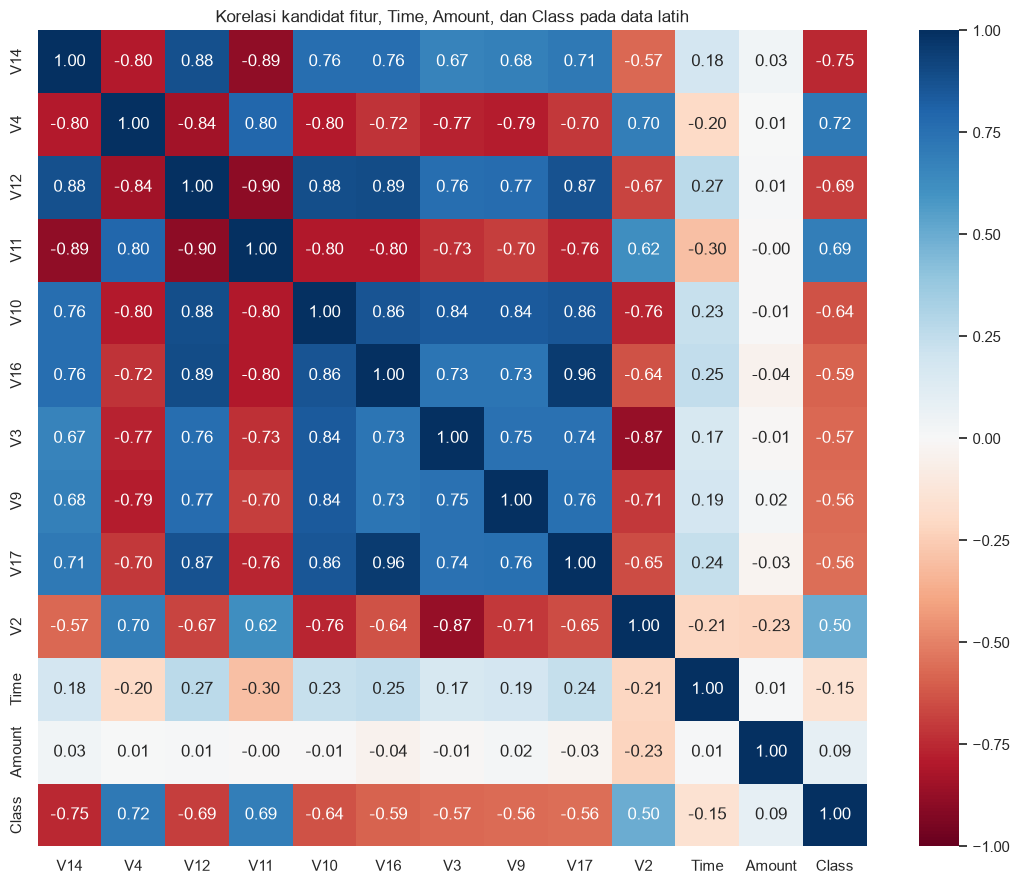

In [23]:
plt.figure(figsize=(11, 9))
kolom_heatmap = kandidat_10 + ["Time", "Amount", "Class"]
sns.heatmap(data_korelasi[kolom_heatmap].corr(), annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1)
plt.title("Korelasi kandidat fitur, Time, Amount, dan Class pada data latih")
plt.tight_layout()
plt.show()

## 6.2 Bandingkan tiga set fitur

StratifiedKFold membagi 784 transaksi latih menjadi lima bagian. Di setiap putaran, fitur dipilih dari bagian latih lalu model dinilai pada bagian validasi. Kurva precision-recall dihitung dari skor fraud, dan auc menghitung luas trapesium di bawah kurva tersebut.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_seleksi = []

for fold, (indeks_latih, indeks_validasi) in enumerate(cv.split(X_train, y_train), start=1):
    X_fit = X_train.iloc[indeks_latih]
    X_validasi = X_train.iloc[indeks_validasi]
    y_fit = y_train.iloc[indeks_latih]
    y_validasi = y_train.iloc[indeks_validasi]
    fitur_10_fold, fitur_9_fold = pilih_fitur(X_fit, y_fit)

    daftar_fitur = [X_train.columns.tolist(), fitur_10_fold, fitur_9_fold]
    nama_set = ["30 fitur", "10 kandidat", "Set ringkas"]

    for nama, fitur in zip(nama_set, daftar_fitur):
        model = RandomForestClassifier(n_estimators=300, random_state=42)
        model.fit(X_fit[fitur], y_fit)
        skor = model.predict_proba(X_validasi[fitur])[:, 1]
        precision, recall, batas = precision_recall_curve(y_validasi, skor)
        nilai_pr_auc = auc(recall, precision)
        hasil_seleksi.append([fold, nama, len(fitur), nilai_pr_auc])

hasil_seleksi = pd.DataFrame(hasil_seleksi, columns=["Fold", "Set fitur", "Jumlah fitur", "PR-AUC"])
ringkasan_seleksi = hasil_seleksi.groupby("Set fitur")["PR-AUC"].agg(["mean", "std"])
display(ringkasan_seleksi.round(4))

,mean,std
Set fitur,,
10 kandidat,0.9804,0.0068
30 fitur,0.9822,0.0063
Set ringkas,0.9798,0.0083


**Keputusan fitur.** PR-AUC validasi set lengkap sekitar 0,9822, top 10 sekitar 0,9804, dan set ringkas sekitar 0,9798. Tim mempertahankan 30 fitur untuk tahap pemodelan karena rata-rata skor validasi tertinggi pada percobaan ini. Time dan Amount tetap digunakan bersama V1-V28. Class menjadi target.

Set ringkas tetap dicatat sebagai alternatif dengan sembilan fitur, yaitu V14, V4, V12, V11, V10, V16, V3, V9, dan V2. Selisih dengan set lengkap sekitar 0,25 poin persentase.

# 7. Modeling

## 7.1 Model Dasar (Baseline)

Sebagai konfigurasi dasar, SVM linear diuji dengan parameter penalti awal $C=1$, sedangkan Random Forest menggunakan 100 pohon keputusan dengan batas kedalaman maksimal 5. Seluruh model dasar dilatih menggunakan 784 data latih. Data uji sebanyak 197 transaksi tetap diisolasi sampai konfigurasi terbaik terpilih.

In [25]:
from sklearn.svm import SVC

svm_awal = SVC(kernel="linear", C=1.0)
svm_awal.fit(X_train_scaled, y_train)
print("SVM awal berhasil dilatih.")
print("Support vector per kelas:", svm_awal.n_support_)

SVM awal berhasil dilatih.
Support vector per kelas: [59 52]


In [26]:
rf_awal = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_awal.fit(X_train, y_train)
print("Random Forest awal berhasil dilatih.")

Random Forest awal berhasil dilatih.


## 7.2 Tambahan validasi SVM untuk memilih C

Uji C sebesar 0,1; 1; dan 10 pada lima fold yang sama. Setiap fold membuat scaler baru agar rata-rata, simpangan baku, median, dan IQR hanya dipelajari dari bagian latih fold. Cara scaling sama dengan bab 5. Nilai PR-AUC dihitung dari decision_function SVM.

In [27]:
hasil_svm = []

for nilai_c in [0.1, 1.0, 10.0]:
    skor_fold = []
    for indeks_latih, indeks_validasi in cv.split(X_train, y_train):
        X_fit = X_train.iloc[indeks_latih].copy()
        X_validasi = X_train.iloc[indeks_validasi].copy()
        y_fit = y_train.iloc[indeks_latih]
        y_validasi = y_train.iloc[indeks_validasi]

        scaler_amount_fold = RobustScaler()
        X_fit[["Amount"]] = scaler_amount_fold.fit_transform(X_fit[["Amount"]])
        X_validasi[["Amount"]] = scaler_amount_fold.transform(X_validasi[["Amount"]])

        scaler_standard_fold = StandardScaler()
        X_fit[kolom_standard] = scaler_standard_fold.fit_transform(X_fit[kolom_standard])
        X_validasi[kolom_standard] = scaler_standard_fold.transform(X_validasi[kolom_standard])

        svm = SVC(kernel="linear", C=nilai_c)
        svm.fit(X_fit, y_fit)
        skor = svm.decision_function(X_validasi)
        precision, recall, batas = precision_recall_curve(y_validasi, skor)
        skor_fold.append(auc(recall, precision))

    hasil_svm.append([nilai_c, np.mean(skor_fold), np.std(skor_fold)])

tabel_svm = pd.DataFrame(hasil_svm, columns=["C", "PR-AUC CV", "SD PR-AUC CV"])
display(tabel_svm.round(4))

,C,PR-AUC CV,SD PR-AUC CV
0,0.1,0.9849,0.0058
1,1.0,0.9832,0.0074
2,10.0,0.9836,0.0074


## 7.3 Tambahan validasi Random Forest

Uji kombinasi 100 atau 300 pohon dan kedalaman maksimum 5 atau None. None membuat pohon tumbuh tanpa batas kedalaman eksplisit. Random Forest memakai fitur pada skala asal. Semua konfigurasi diuji pada lima pembagian yang sama dengan SVM.

In [28]:
hasil_rf = []

for jumlah_pohon in [100, 300]:
    for kedalaman in [5, None]:
        skor_fold = []
        for indeks_latih, indeks_validasi in cv.split(X_train, y_train):
            X_fit = X_train.iloc[indeks_latih]
            X_validasi = X_train.iloc[indeks_validasi]
            y_fit = y_train.iloc[indeks_latih]
            y_validasi = y_train.iloc[indeks_validasi]

            rf = RandomForestClassifier(
                n_estimators=jumlah_pohon, max_depth=kedalaman, random_state=42
            )
            rf.fit(X_fit, y_fit)
            skor = rf.predict_proba(X_validasi)[:, 1]
            precision, recall, batas = precision_recall_curve(y_validasi, skor)
            skor_fold.append(auc(recall, precision))

        hasil_rf.append([jumlah_pohon, kedalaman, np.mean(skor_fold), np.std(skor_fold)])

tabel_rf = pd.DataFrame(hasil_rf, columns=["Jumlah pohon", "Kedalaman", "PR-AUC CV", "SD PR-AUC CV"])
display(tabel_rf.round(4))

,Jumlah pohon,Kedalaman,PR-AUC CV,SD PR-AUC CV
0,100,5.0,0.9822,0.0055
1,100,NaN,0.9818,0.0054
2,300,5.0,0.9820,0.0058
3,300,NaN,0.9822,0.0056


## 7.4 Pilih konfigurasi, lalu latih model akhir

Ambil baris dengan rata-rata PR-AUC CV tertinggi untuk masing-masing algoritma. Selanjutnya fit memakai seluruh 784 transaksi latih. Nilai kedalaman yang kosong pada tabel berarti None. Model pilihan ditentukan dari skor validasi sebelum hasil uji dibuka.

In [29]:
svm_terbaik = tabel_svm.loc[tabel_svm["PR-AUC CV"].idxmax()]
c_terbaik = svm_terbaik["C"]
model_svm = SVC(kernel="linear", C=c_terbaik)
model_svm.fit(X_train_scaled, y_train)

rf_terbaik = tabel_rf.loc[tabel_rf["PR-AUC CV"].idxmax()]
jumlah_pohon_terbaik = int(rf_terbaik["Jumlah pohon"])
if pd.isna(rf_terbaik["Kedalaman"]):
    kedalaman_terbaik = None
else:
    kedalaman_terbaik = int(rf_terbaik["Kedalaman"])

model_rf = RandomForestClassifier(
    n_estimators=jumlah_pohon_terbaik, max_depth=kedalaman_terbaik, random_state=42
)
model_rf.fit(X_train, y_train)

perbandingan_cv = pd.DataFrame({
    "Model": ["SVM linear", "Random Forest"],
    "PR-AUC CV": [svm_terbaik["PR-AUC CV"], rf_terbaik["PR-AUC CV"]],
    "SD PR-AUC CV": [svm_terbaik["SD PR-AUC CV"], rf_terbaik["SD PR-AUC CV"]],
})
display(perbandingan_cv.round(4))

if svm_terbaik["PR-AUC CV"] >= rf_terbaik["PR-AUC CV"]:
    nama_terpilih = "SVM linear"
else:
    nama_terpilih = "Random Forest"
print("Model pilihan berdasarkan validasi:", nama_terpilih)

,Model,PR-AUC CV,SD PR-AUC CV
0,SVM linear,0.9849,0.0058
1,Random Forest,0.9822,0.0056


Model pilihan berdasarkan validasi: SVM linear


**Interpretasi validasi pada eksekusi tersimpan.** SVM linear dengan C=0,1 memperoleh PR-AUC CV sekitar 0,9849. Random Forest dengan 300 pohon dan kedalaman None memperoleh sekitar 0,9822. SVM dipilih berdasarkan rata-rata tersebut. Selisihnya kecil dibanding variasi antar-fold sehingga hasil dibaca sebagai perbandingan pada subset ini.

# 8. Evaluasi

## 8.1 Prediksi kedua model pada data uji

predict menghasilkan label normal/fraud. decision_function SVM dan predict_proba Random Forest menghasilkan skor untuk kurva precision-recall. SVM memakai X_test_scaled dengan scaler dari data latih, sedangkan Random Forest memakai X_test pada skala asal.

In [30]:
y_pred_svm = model_svm.predict(X_test_scaled)
skor_svm = model_svm.decision_function(X_test_scaled)

y_pred_rf = model_rf.predict(X_test)
skor_rf = model_rf.predict_proba(X_test)[:, 1]

from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
skor_baseline = baseline.predict_proba(X_test)[:, 1]

## 8.2 Laporan Metrik Klasifikasi

Evaluasi kinerja difokuskan utama pada transaksi penipuan (`Class = 1`). Precision mengukur tingkat ketepatan transaksi yang diberi tanda bahaya (alarm fraud), sedangkan Recall mengukur seberapa banyak total transaksi fraud riil yang berhasil tertangkap oleh model.

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification report SVM")
print(classification_report(y_test, y_pred_svm, target_names=["Normal", "Fraud"]))

print("Classification report Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Fraud"]))

Classification report SVM
              precision    recall  f1-score   support

      Normal       0.89      0.99      0.94       102
       Fraud       0.99      0.86      0.92        95

    accuracy                           0.93       197
   macro avg       0.94      0.93      0.93       197
weighted avg       0.94      0.93      0.93       197

Classification report Random Forest
              precision    recall  f1-score   support

      Normal       0.90      0.98      0.94       102
       Fraud       0.98      0.88      0.93        95

    accuracy                           0.93       197
   macro avg       0.94      0.93      0.93       197
weighted avg       0.94      0.93      0.93       197



## 8.3 Tabel Metrik Pembanding

Tabel berikut menyajikan perbandingan metrik evaluasi antara model baseline dummy, SVM linear, dan Random Forest pada data uji. Luas area di bawah kurva Precision-Recall (PR-AUC) dihitung menggunakan integrasi aturan trapesium, sementara skor Average Precision (AP) disertakan sebagai metrik pelengkap.

In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, average_precision_score

nama_model = ["Baseline konstan", "SVM linear", "Random Forest"]
daftar_prediksi = [y_pred_baseline, y_pred_svm, y_pred_rf]
daftar_skor = [skor_baseline, skor_svm, skor_rf]
hasil_uji = []

for nama, prediksi, skor in zip(nama_model, daftar_prediksi, daftar_skor):
    precision, recall, batas = precision_recall_curve(y_test, skor)
    tn, fp, fn, tp = confusion_matrix(y_test, prediksi).ravel()
    hasil_uji.append({
        "Model": nama,
        "PR-AUC": auc(recall, precision),
        "AP": average_precision_score(y_test, skor),
        "Precision fraud": precision_score(y_test, prediksi, zero_division=0),
        "Recall fraud": recall_score(y_test, prediksi, zero_division=0),
        "F1 fraud": f1_score(y_test, prediksi, zero_division=0),
        "Accuracy": accuracy_score(y_test, prediksi),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

tabel_uji = pd.DataFrame(hasil_uji).set_index("Model")
display(tabel_uji.round(4))

,PR-AUC,AP,Precision fraud,Recall fraud,F1 fraud,Accuracy,TN,FP,FN,TP
Model,,,,,,,,,,
Baseline konstan,0.7411,0.4822,0.0000,0.0000,0.0000,0.5178,102,0,95,0
SVM linear,0.9813,0.9814,0.9880,0.8632,0.9213,0.9289,101,1,13,82
Random Forest,0.9852,0.9853,0.9767,0.8842,0.9282,0.9340,100,2,11,84


## 8.4 Confusion matrix dan kurva precision-recall

Baris confusion matrix menunjukkan kelas sebenarnya dan kolom menunjukkan prediksi. False negative adalah fraud yang terlewat, sedangkan false positive adalah transaksi normal yang mendapat alarm fraud.

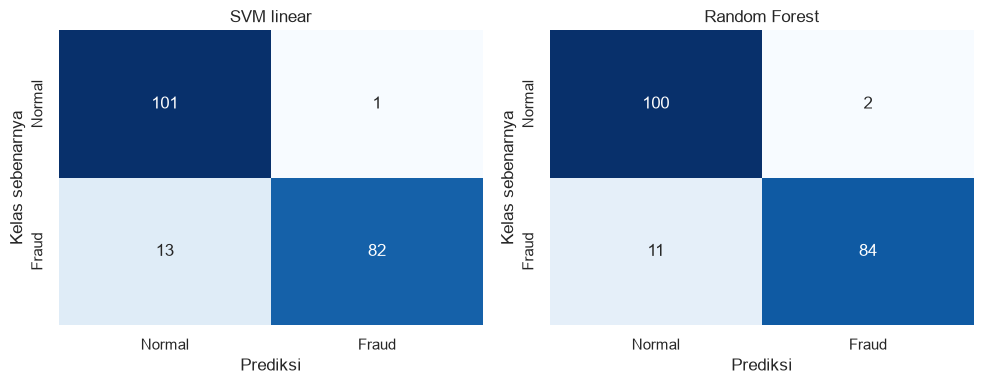

In [33]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"], ax=axes[0])
axes[0].set_title("SVM linear")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Kelas sebenarnya")

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"], ax=axes[1])
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Kelas sebenarnya")
plt.tight_layout()
plt.show()

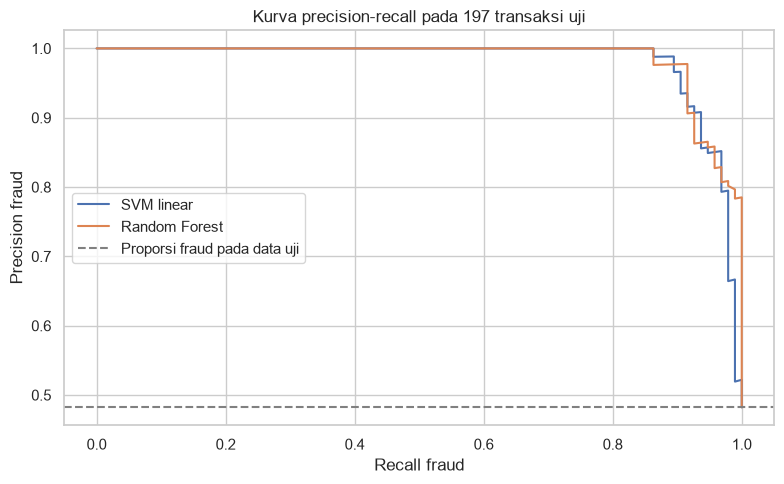

In [34]:
precision_svm, recall_svm, batas_svm = precision_recall_curve(y_test, skor_svm)
precision_rf, recall_rf, batas_rf = precision_recall_curve(y_test, skor_rf)

plt.figure(figsize=(8, 5))
plt.plot(recall_svm, precision_svm, label="SVM linear")
plt.plot(recall_rf, precision_rf, label="Random Forest")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Proporsi fraud pada data uji")
plt.xlabel("Recall fraud")
plt.ylabel("Precision fraud")
plt.title("Kurva precision-recall pada 197 transaksi uji")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi hasil uji.** SVM menemukan 82 dari 95 fraud, melewatkan 13 fraud, dan memberikan satu alarm keliru pada transaksi normal. Precision fraud sekitar 98,80% dan recall sekitar 86,32%.

Random Forest menemukan 84 fraud, melewatkan 11 fraud, dan memberikan dua alarm keliru. PR-AUC uji Random Forest sekitar 0,9852, sedangkan SVM sekitar 0,9813. Pilihan model tetap mengikuti validasi data latih, yaitu SVM linear. Perbedaan ranking antar pembagian sampel dicatat dalam evaluasi. Penentuan threshold berbasis biaya menjadi pekerjaan lanjutan.

## 8.5 Kepentingan Fitur (Feature Importance) Random Forest

Tingkat kepentingan fitur dihitung berdasarkan rata-rata penurunan *impurity* (Gini impurity) di setiap pemisahan simpul pohon pada Random Forest. Mengingat fitur V1-V28 merupakan komponen anonim hasil PCA, urutan bobot ini mencerminkan kontribusi matematis fitur dalam memisahkan transaksi normal dan fraud.

,Fitur,Importance
14,V14,0.1533
10,V10,0.1293
4,V4,0.1108
12,V12,0.1036
17,V17,0.0786
11,V11,0.0643
16,V16,0.0588
3,V3,0.0523
2,V2,0.0259
9,V9,0.0259


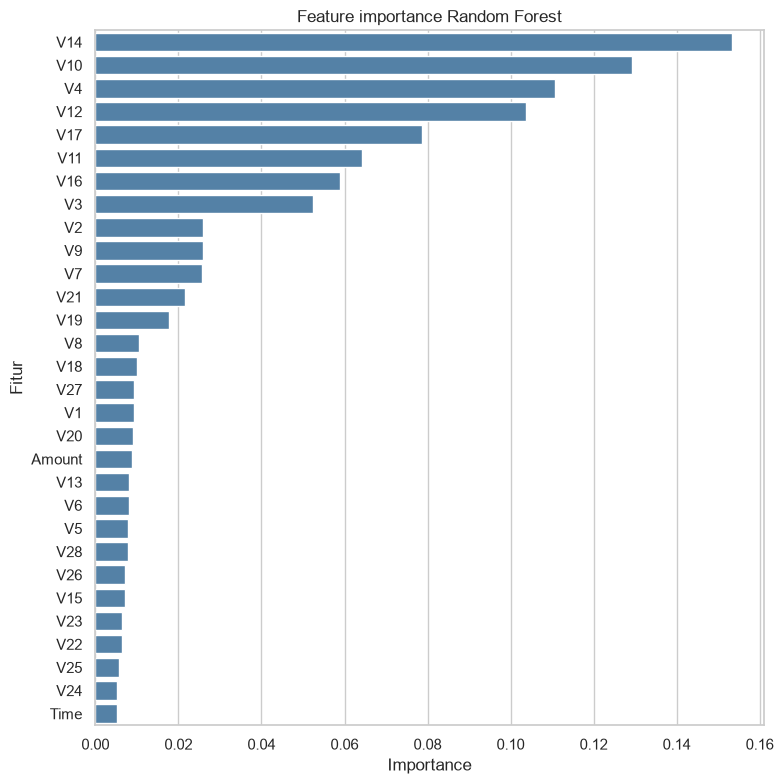

In [35]:
feature_importance = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": model_rf.feature_importances_,
})
feature_importance = feature_importance.sort_values("Importance", ascending=False)
display(feature_importance.round(4))

plt.figure(figsize=(8, 8))
sns.barplot(data=feature_importance, x="Importance", y="Fitur", color="steelblue")
plt.title("Feature importance Random Forest")
plt.tight_layout()
plt.show()

# 9. Konklusi

1. Model klasifikasi digunakan untuk membantu analis memprioritaskan pemeriksaan transaksi berisiko fraud.
2. Dari 1.000 transaksi awal, 19 duplikat berlebih dihapus sehingga tersisa 981. Kandidat outlier dan transaksi bernilai nol dipertahankan. Data dibagi menjadi 784 latih dan 197 uji.
3. Tim mempertahankan 30 fitur berdasarkan eksperimen PR-AUC validasi. Set lengkap mendapat sekitar 0,9822, sementara versi 9 fitur mendapat sekitar 0,9798.
4. SVM linear C=0,1 dipilih berdasarkan PR-AUC validasi sekitar 0,9849. Pada data uji, SVM mendapat PR-AUC sekitar 0,9813, precision fraud 98,80%, dan recall fraud 86,32%.
5. Random Forest memperoleh PR-AUC uji sekitar 0,9852 dan menemukan dua fraud lebih banyak dengan satu alarm keliru tambahan. Hasil ini dilaporkan bersama hasil validasi agar perbandingan lengkap.
6. Subset hampir seimbang, data hanya dua hari pada 2013, dan fitur anonim. Hasil belum membuktikan penghematan finansial atau performa pada kondisi transaksi saat ini.
7. Pengujian pada distribusi yang lebih realistis serta penetapan biaya kesalahan dan threshold operasional menjadi tindak lanjut.

Angka penjelasan Markdown mengikuti eksekusi yang tersimpan. Jika data atau konfigurasi diubah, cocokkan kembali narasi dengan tabel hasil terbaru.

## Kesesuaian dengan panduan dan rujukan

| Bagian panduan proyek akhir | Bukti di notebook |
|---|---|
| Business Understanding | Bab 1, pertanyaan, stakeholder, tujuan, risiko, dan metrik |
| Data Gathering | Bab 2, sumber, desain subset, dan data dictionary |
| EDA dengan interpretasi | Bab 3, statistik, distribusi, korelasi, dan penjelasan grafik |
| Cleaning dan preprocessing | Bab 4-5, audit sebelum/sesudah serta scaling dari data latih |
| Feature Selection | Bab 6, alasan per fitur dan validasi 30/10/9 fitur |
| Modeling | Bab 7, SVM dan Random Forest dari Modul 6-7 beserta parameter dan alasan |
| Evaluasi | Bab 8, tabel metrik, confusion matrix, kurva PR, dan feature importance |
| Konklusi | Bab 9, jawaban bisnis, keputusan, makna metrik, dan batasan |

**Rujukan lokal perkuliahan**

- [Panduan Proyek Akhir Praktikum Data Science 2026/2027](rujukan/panduan%20proyek/Panduan%20Proyek%20Akhir%20Praktikum%20Data%20Science%202026_2027.pdf), halaman 3-5.
- [Modul 6 SVM](rujukan/modul/Modul%206%20DS_SVM.pdf), bagian scaling, pembagian data, SVC linear, dan Pipeline, halaman 3-11.
- [Modul 7 Random Forest](rujukan/modul/Modul%207%20DS_Classification%20II.pdf), parameter dan feature importance, halaman 1-5.

**Sumber data dan dokumentasi**

- [Kaggle ULB Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).
- [Repository proyek](https://github.com/RaflinMadani/Credit-Card-Fraud-Detection).
- [Metrik precision-recall](https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-f-measure-metrics).

Notebook menjadi satu berkas yang dijalankan berurutan sampai konklusi. Repository pengumpulan juga memerlukan dataset dan README yang mencantumkan anggota, kontribusi, sumber data, dependensi, serta cara menjalankan. Tanggal pengumpulan dalam panduan adalah 22 November 2026.